In [ ]:
%pip install --no-cache-dir --force-reinstall numpy==2.2.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 106.1 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
landingai 0.3.49 requires numpy<2.0.0,>=1.21.0, but you have numpy 2.2.6 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.


In [ ]:
import numpy
print(numpy.__version__)

2.2.6


In [ ]:
%pip install -q landingai pillow easyocr gTTS matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.11.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
google-adk 2.7.1 requires tenacity<10,>=9, but you have tenacity 8.5.0 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
shap 0.54.1 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
hugg

In [ ]:
import re
import getpass
from datetime import date
from pathlib import Path

import numpy as np
import easyocr

from PIL import Image, ImageDraw
from IPython.display import display, Markdown, Audio
from gtts import gTTS

from landingai.predict import Predictor

In [ ]:
endpoint_id = "e8d798e7-1445-4c5f-9b45-b8ba05131e9c"

api_key = "land_sk_wMRSaykMtiMVT2Yyx4q1pdk1oa0ciS6os7y88pi7aG6WyMmfOg"

predictor = Predictor(endpoint_id, api_key=api_key)

reader = easyocr.Reader(["en"], gpu=False)

print("Medicine Label Assistant initialized.")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteMedicine Label Assistant initialized.


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving medicine_0147_png.rf.75aae4cfd01d46310f42de75efcf1939.jpg to medicine_0147_png.rf.75aae4cfd01d46310f42de75efcf1939.jpg


Detection Results:
[ObjectDetectionPrediction(score=0.9809475541114807, label_name='medicine-label', label_index=1, id='5883e056-9226-4a94-997f-4873040600b3', bboxes=(34, 286, 198, 309)), ObjectDetectionPrediction(score=0.9794822335243225, label_name='medicine-label', label_index=1, id='86ebf2c6-3ba8-4e98-a93b-8cfb65237393', bboxes=(34, 406, 125, 428)), ObjectDetectionPrediction(score=0.9793738126754761, label_name='medicine-label', label_index=1, id='ed5dd624-cabc-428a-af29-aa00d4b40ff7', bboxes=(34, 331, 220, 356)), ObjectDetectionPrediction(score=0.9708918333053589, label_name='medicine-label', label_index=1, id='e8d9c8a4-93e6-4a14-806b-933876bc5823', bboxes=(33, 216, 153, 241)), ObjectDetectionPrediction(score=0.9581498503684998, label_name='medicine-label', label_index=1, id='75c86e60-3061-4ac0-8364-95cd5633d3d9', bboxes=(34, 246, 375, 274)), ObjectDetectionPrediction(score=0.9322929382324219, label_name='medicine-label', label_index=1, id='00e66ce9-f106-4405-99b3-d03a44475bdf', b

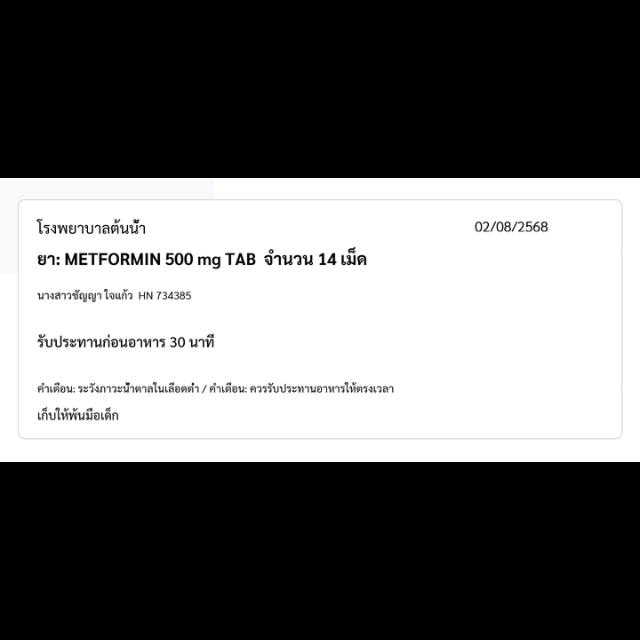

In [ ]:
image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

predictions = predictor.predict(image)

print("Detection Results:")
print(predictions)

display(image)

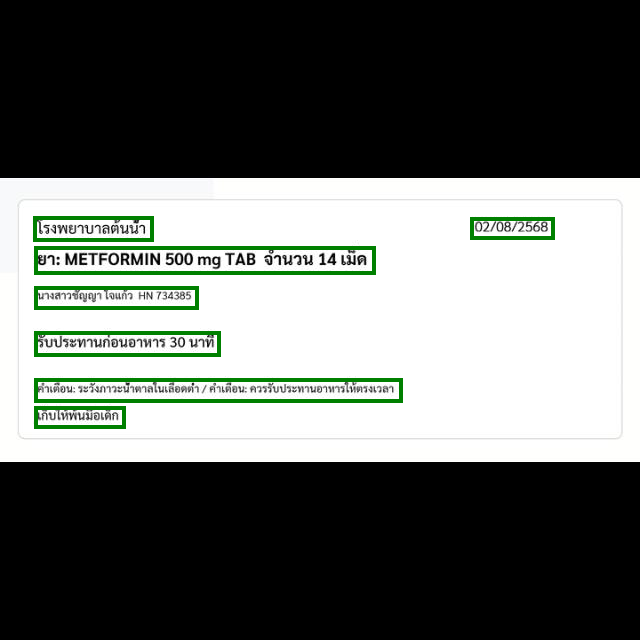

Detected regions: 7


In [ ]:
detected_image = image.copy()
draw = ImageDraw.Draw(detected_image)

regions = []

for prediction in predictions:
    if prediction.score < 0.25:
        continue

    x1, y1, x2, y2 = map(int, prediction.bboxes)

    regions.append((x1, y1, x2, y2))

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="green",
        width=4
    )

display(detected_image)

print("Detected regions:", len(regions))

In [ ]:
all_text = []

if not regions:
    regions = [(0, 0, image.width, image.height)]

for x1, y1, x2, y2 in regions:

    cropped = image.crop((x1, y1, x2, y2))

    results = reader.readtext(np.array(cropped))

    for box, text, confidence in results:
        all_text.append(text)
        print(f"{text} | Confidence: {confidence:.2f}")

full_text = " ".join(all_text)

print("\nExtracted Medicine Label Text:")
print(full_text)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


174a17d00yn Iqurn HN 734385 | Confidence: 0.07
Liuluviuiialan | Confidence: 0.17
JUUse0JuI0u07175 30 uam | Confidence: 0.05
Usawununanuin | Confidence: 0.23
87: METFORMIN 500 mg TAB | Confidence: 0.77
14 lia | Confidence: 0.40
G1u7u | Confidence: 0.17
Animau: J2Tannazuhataluizoawin | Confidence: 0.01
Ainirou: A77TUua-M71071/734i07*(287 | Confidence: 0.01
02/08/2568 | Confidence: 0.37

Extracted Medicine Label Text:
174a17d00yn Iqurn HN 734385 Liuluviuiialan JUUse0JuI0u07175 30 uam Usawununanuin 87: METFORMIN 500 mg TAB 14 lia G1u7u Animau: J2Tannazuhataluizoawin Ainirou: A77TUua-M71071/734i07*(287 02/08/2568


In [ ]:
def extract_information(text):

    information = {
        "medicine_name": None,
        "expiry_date": None,
        "manufacturing_date": None,
        "batch_number": None,
        "strength": None
    }

    name = re.search(
        r"\b(METFORMIN|PARACETAMOL|IBUPROFEN|AMOXICILLIN)\b",
        text,
        re.IGNORECASE
    )

    if name:
        information["medicine_name"] = name.group(1).upper()

    expiry = re.search(
        r"(?:EXP|EXPIRY|EXPIRES)[\s:.-]*([A-Z0-9/-]+)",
        text,
        re.IGNORECASE
    )

    if expiry:
        information["expiry_date"] = expiry.group(1)


    manufacturing = re.search(
        r"(?:MFG|MFD)[\s:.-]*([A-Z0-9/-]+)",
        text,
        re.IGNORECASE
    )

    if manufacturing:
        information["manufacturing_date"] = manufacturing.group(1)


    batch = re.search(
        r"(?:BATCH|B\.?NO|LOT)[\s:.-]*([A-Z0-9-]+)",
        text,
        re.IGNORECASE
    )

    if batch:
        information["batch_number"] = batch.group(1)


    strengths = re.findall(
        r"\d+(?:\.\d+)?\s*(?:mg|mcg|ml|g|IU)",
        text,
        re.IGNORECASE
    )

    if strengths:
        information["strength"] = ", ".join(strengths)

    return information


medicine_info = extract_information(full_text)

for key, value in medicine_info.items():
    print(f"{key}: {value or 'Not detected'}")

medicine_name: METFORMIN
expiry_date: Not detected
manufacturing_date: Not detected
batch_number: Not detected
strength: 500 mg


In [ ]:
def check_expiry(expiry_text):

    if not expiry_text:
        return "Expiry date could not be identified."

    months = {
        "JAN": 1, "FEB": 2, "MAR": 3,
        "APR": 4, "MAY": 5, "JUN": 6,
        "JUL": 7, "AUG": 8, "SEP": 9,
        "OCT": 10, "NOV": 11, "DEC": 12
    }

    match = re.search(
        r"([A-Z]{3})[A-Z]*\s*(\d{2,4})",
        expiry_text.upper()
    )

    if match:
        month = months.get(match.group(1))
        year = int(match.group(2))

    else:
        match = re.search(
            r"(\d{1,2})[/-](\d{2,4})",
            expiry_text
        )

        if not match:
            return "Expiry date format not recognized."

        month = int(match.group(1))
        year = int(match.group(2))

    if year < 100:
        year += 2000

    if not month or not 1 <= month <= 12:
        return "Invalid expiry date."

    today = date.today()

    if (year, month) < (today.year, today.month):
        return "EXPIRED"

    return "NOT EXPIRED (verify exact expiry date on packaging)"


expiry_status = check_expiry(medicine_info["expiry_date"])

print("Medicine Expiry Status:", expiry_status)

Medicine Expiry Status: Expiry date could not be identified.


In [ ]:
def generate_response(info, status):

    response = f"""
Medicine Label Cognitive Assistant

Medicine Name: {info['medicine_name'] or 'Not detected'}

Strength:{info['strength'] or 'Not detected'}

Manufacturing Date: {info['manufacturing_date'] or 'Not detected'}

Expiry Date:{info['expiry_date'] or 'Not detected'}

Batch Number:{info['batch_number'] or 'Not detected'}

Expiry Status:{status}

The information above was extracted using image recognition
and optical character recognition.

Please verify the extracted information against the original
packaging or consult a pharmacist before using the medicine.
"""

    return response


assistant_response = generate_response(
    medicine_info,
    expiry_status
)

print(assistant_response)


Medicine Label Cognitive Assistant

Medicine Name: METFORMIN

Strength: 500 mg

Manufacturing Date: Not detected

Expiry Date: Not detected

Batch Number: Not detected

Expiry Status: Expiry date could not be identified.

The information above was extracted using image recognition
and optical character recognition.

Please verify the extracted information against the original
packaging or consult a pharmacist before using the medicine.



The dataset I used had the suitable number of images to be trained on the free tier of landing lens but the language of the medicine labels was not english hence couldn't extract most information. Extraction works fine for the medicine name and power.
